# Ulrich atlas → our data: the fibroblast-subtype mapping, end to end

**What this is.** One auditable summary of the whole Hammoud/Ulrich mapping arm: what the atlas
contains, how we look for it in our data, what the controls say the numbers mean, what we found in
human, what we found in mouse, and what we did not find.

**How to read it.** Every quantitative claim is recomputed here from the file that produced it and
checked against the recorded value with `verify()`. The run ends with a check summary; if it is not
`0 MISMATCH`, do not quote the notebook.

**What it does NOT do.** No `.h5ad` is opened, no clustering is run, nothing is refit. This reads
the tables written by the Slurm jobs, so it executes in seconds and can run on a login node.

| section | question it answers |
|---|---|
| §1 | What does the atlas actually contain, and which subtypes are findable *in principle*? |
| §2 | What is the metric, and what are its two traps? |
| §3 | What do the controls say a score means? (the calibration ladder) |
| §4 | The human result, at three levels of independence |
| §5 | The mouse result, and the three readouts that fail |
| §6 | What we do not have evidence for |

Canonical execution on the cluster:

```bash
cd /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud
jupyter nbconvert --to notebook --execute --inplace hammoud_atlas_mapping_SUMMARY.ipynb
```

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

# ---------- data root: the real project dir on the cluster, else a local mirror ----------
ROOTS = [Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud"),
         Path("nbdata"), Path("../nbdata"), Path(".")]
SUBS  = ["", "fib_positive_controls", "fib_continuous_correspondence",
         "fib_refined_and_clusterfree", "fib_resolution_crosswalk",
         "fib_centroid_results", "fib_centroid_results_mouse"]
def find(name):
    for r in ROOTS:
        for s in SUBS:
            p = r / s / name
            if p.exists(): return p
    raise FileNotFoundError(name)
print("data root:", next(r for r in ROOTS if r.exists()).resolve())

_checks = []
def verify(label, got, expected, tol=0.0, note=""):
    ok = (abs(got-expected) <= tol) if isinstance(got,(int,float,np.floating)) else (got == expected)
    _checks.append((label, got, expected, "PASS" if ok else "MISMATCH"))
    print(f"[{'PASS ' if ok else 'MISMATCH'}] {label}: recomputed={got}  recorded={expected}"
          + (f"   ({note})" if note else ""))
def check_summary():
    d = pd.DataFrame(_checks, columns=["claim","recomputed","recorded","status"])
    n = int((d.status=="MISMATCH").sum())
    print(f"\n{'='*74}\n{len(d)} checks | {n} MISMATCH\n{'='*74}")
    if n: display(d[d.status=="MISMATCH"])
    return d

data root: /Users/nickhilgert/.claude-science/orgs/06f88a99-9105-4941-a8cf-87e6b02aff65/workspaces/03a8c71c-ed3b-4b58-ac4a-11dd1108c24f/nbdata


---
## §1 What the atlas contains, and which subtypes are findable in principle

Ulrich et al. 2024 (PNAS 121:e2404775121) is full-thickness human uterus, single-**cell**, 20
donors, 39 subtypes, of which **11 are stromal**. Our data is menstrual-phase endometrium,
single-**nucleus** plus Slide-tags, 2 donors.

This section comes first because it **predicts the rest of the notebook**. Ranking genes by the
atlas's published `avg_log2FC` answers "is this gene up in this subtype"; it does not answer "does
this gene tell me which subtype I am looking at". So for every gene we compute a **specificity
margin** — its centroid expression in a subtype minus its highest expression in any *other*
stromal subtype — and a second margin against all 38 other subtypes including epithelium,
endothelium and immune. A gene clearing the first but failing the second is not usable in whole
tissue.

In [3]:
spec = pd.read_csv(find("hammoud_stromal_marker_specificity_full.csv"))
ORD  = [f"Stro-{n}" for n in range(1, 12)]
summ = (spec.groupby("subtype")
            .apply(lambda d: pd.Series({
                "n_margin_gt_0.5":  int((d.margin_stromal > 0.5).sum()),
                "n_also_vs_all39":  int((d.margin_all39   > 0.5).sum()),
                "best_margin":      round(d.margin_stromal.max(), 3),
                "top_gene":         d.loc[d.margin_stromal.idxmax(), "gene"]}), include_groups=False)
            .reindex(ORD))
LABEL = {"Stro-1":"PV MYH11 FOXC1hi","Stro-2":"PV MYH11 FOXC1lo","Stro-3":"PV STEAP4 (pericyte)",
         "Stro-4":"vascular progenitor","Stro-5":"RUNX3+ 'fibroblast'","Stro-6":"uSMC",
         "Stro-7":"C7 fibroblast","Stro-8":"dS1 early decidual","Stro-9":"dS2 mid decidual",
         "Stro-10":"dS3 late decidual","Stro-11":"stromal progenitor"}
summ.insert(0, "ulrich_label", [LABEL[i] for i in summ.index])
display(summ)

verify("Stro-7 has the most genes holding against all 39 subtypes of any FIBROBLAST subtype",
       summ.loc["Stro-7", "n_also_vs_all39"], 36, note="the structural reason C7 maps everywhere")
verify("dS2 has no gene clearing a 0.5 specificity margin", summ.loc["Stro-9","n_margin_gt_0.5"], 0)
verify("dS3 has no gene clearing a 0.5 specificity margin", summ.loc["Stro-10","n_margin_gt_0.5"], 0)
verify("Stro-5's markers are useless in whole tissue despite 66 clearing the stromal margin",
       summ.loc["Stro-5","n_also_vs_all39"], 0,
       note="its centroid is NK/T + mast (GNLY, TPSB2, TPSAB1, GZMA) plus PTPRC")
verify("Stro-4's markers are likewise all shared with endothelium",
       summ.loc["Stro-4","n_also_vs_all39"], 0, note="ACKR1, CLDN5, VWF, EGFL7 — a transitional subtype")

                 ulrich_label  n_margin_gt_0.5  n_also_vs_all39  best_margin top_gene
subtype                                                                              
Stro-1       PV MYH11 FOXC1hi               31               11        0.951   HSPA1A
Stro-2       PV MYH11 FOXC1lo                5                3        0.853     GPX3
Stro-3   PV STEAP4 (pericyte)                8                6        1.274   STEAP4
Stro-4    vascular progenitor               38                0        1.794    ACKR1
Stro-5    RUNX3+ 'fibroblast'               66                0        2.667     GNLY
Stro-6                   uSMC               12               10        0.977      DES
Stro-7          C7 fibroblast               51               36        1.872       C7
Stro-8     dS1 early decidual                6                3        0.765   IGFBP1
Stro-9       dS2 mid decidual                0                0        0.392  SCGB1D4
Stro-10     dS3 late decidual                0        

**Read that table before anything else.** Three consequences set up everything below.

1. **Stro-7 is the only stromal subtype with a large tissue-specific signature** — 36 of its 51
   margin-clearing genes hold against all 39 subtypes. This is why the C7 result reproduces in
   every analysis and the others do not.
2. **dS2 and dS3 have no specific markers at all.** Ulrich define dS1→dS2→dS3 as three *stages*
   of one decidualisation process and separate them by regulon activity (STAT3 falling,
   HOXA10/NR2F2 rising), not by marker genes. Any marker-based method asked to identify dS2 is
   attempting something the reference cannot support — so "unresolved" is the correct answer, not
   a shortfall in our data.
3. **Stro-5 and Stro-4 are not fibroblast references.** Stro-5's centroid is NK/T and mast plus
   the pan-leukocyte marker PTPRC (Ulrich themselves note their Imm-2 fibrocytes resemble it);
   Stro-4 is explicitly a stromal-to-endothelial transition. Failing to recover either is correct
   behaviour, and it is what makes them sound negative controls.

---
## §2 The metric, and its two traps

The score is a **double-centred ("contrastive") cosine** between cluster centroids. "Double" does
not mean row-and-column centring of one matrix — it means **each side is centred within itself,
independently, in gene space**:

```python
def contrastive_cosine(Q, A):      # Q: genes x our clusters,  A: genes x atlas subtypes
    Qc = Q.sub(Q.mean(axis=1), axis=0)   # per gene, minus its mean across OUR clusters
    Ac = A.sub(A.mean(axis=1), axis=0)   # per gene, minus its mean across ATLAS subtypes
    return normalize(Qc.T, axis=1) @ normalize(Ac.T, axis=1).T
```

For every gene the question becomes *"is this gene higher here than in the average column on my own
side?"*. Anything that shifts a gene's whole level in one dataset — sequencing depth, nuclear vs
whole-cell capture, species — is absorbed into that side's own mean and drops out. That is what
makes single-nucleus vs single-cell comparison possible at all.

**Trap 1 — the score depends on which columns you pass.** Centring is over the columns present and
the 3,000-gene variance panel is selected over those same columns, so a 6-column run and an
11-column run are *different quantities*. Never compare their numbers.

**Trap 2 — centroids are pseudobulk, not mean-of-logs.** The pipeline averages in linear CP10K
space and then takes log1p. Averaging the log1p values instead shifts every score. (This one cost
a job: the split-half ceiling in §3 came out 0.85 instead of 0.99 until the convention matched.)

In [6]:
cfg = dict(l.strip().split("=",1) for l in find("run_config.txt").read_text().strip().splitlines() if "=" in l)
print("published run_config:", cfg)
F6  = pd.read_csv(find("similarity_fib_contrastive_cosine.csv"),  index_col=0)   # 6 atlas columns
S11 = pd.read_csv(find("similarity_stro_contrastive_cosine.csv"), index_col=0)   # 11 atlas columns
F6.index = F6.index.astype(str); S11.index = S11.index.astype(str)
shared_cols = [c for c in F6.columns if c in S11.columns]
delta = (S11[shared_cols] - F6[shared_cols]).abs().max().max()
print(f"\nsame cluster x same subtype, 6-column vs 11-column run: max |difference| = {delta:.4f}")
verify("the two runs give materially different scores for the SAME pair (trap 1)",
       bool(delta > 0.05), True, note=f"max shift {delta:.3f} — the sink test is not the headline matrix")
verify("panel size is recorded, not implicit", int(cfg["n_panel"]), 3000)

published run_config: {'resolution': '0.5', 'cluster_key': 'leiden_0.5', 'n_panel': '3000', 'min_cluster_n': '100', 'n_boot': '500', 'seed': '0', 'n_obs': '47533', 'n_shared_genes': '33791'}

same cluster x same subtype, 6-column vs 11-column run: max |difference| = 0.1884
[PASS ] the two runs give materially different scores for the SAME pair (trap 1): recomputed=True  recorded=True   (max shift 0.188 — the sink test is not the headline matrix)
[PASS ] panel size is recorded, not implicit: recomputed=3000  recorded=3000


---
## §3 What a score means: the calibration ladder

A cosine of 0.343 is meaningless without knowing what the metric reads when the answer is known.
Both ends are measured here, and **every rung is at the same 6-column width** so the numbers are
comparable (trap 1).

- **Floor — negative control.** Five stromal subtypes that *cannot* be present in a
  fibroblast/decidual object (perivascular Stro-1/2/3, vascular progenitor Stro-4, uSMC Stro-6)
  run through the identical pipeline. Their band is the floor.
- **Ceilings — positive controls.** We cannot split the atlas (Ulrich published centroids, not
  cells), so we map our data onto itself. **Rung 1**: cells of each cluster randomly halved,
  centroids from one half scored against the other — same donors, same assay, the two sides are
  the same populations by construction. **Rung 2**: centroids from one sample scored against
  another sample's cells — same assay, but now with real biological variation.

Rung 1 is an upper bound no cross-dataset mapping can reach. It brackets the scale; it is **not** a
pass mark.

In [8]:
h1 = pd.read_csv(find("human_rung1_splithalf_per_split.csv"))
h2 = pd.read_csv(find("human_rung2_crosssample_per_pair.csv"))
pcs = pd.read_csv(find("positive_control_selfcheck.csv"))
print(f"positive-control job self-checks: {len(pcs)} | "
      f"{int((pcs.status=='MISMATCH').sum())} MISMATCH")

# own_score is the self-match looked up BY NAME; a positional diagonal mixes in non-matches
CEIL1, CEIL2 = float(h1.own_score.mean()), float(h2.own_score.mean())
NEG_LO, NEG_HI = 0.0813, 0.1235
REAL7, REAL10 = float(F6.max()[[c for c in F6.columns if c.startswith("Stro-7")][0]]), \
                float(F6.max()[[c for c in F6.columns if c.startswith("Stro-10")][0]])
print(f"\nrung 1 split-half   : self {CEIL1:.4f}  (sd {h1.own_score.std():.4f}, "
      f"min {h1.own_score.min():.4f})  best non-self {h1.runner_up_score.mean():+.4f}")
print(f"rung 2 cross-sample : self {CEIL2:.4f}  (sd {h2.own_score.std():.4f}, "
      f"min {h2.own_score.min():.4f})  best non-self {h2.runner_up_score.mean():+.4f}")
print(f"rung 3 observed     : Stro-7 {REAL7:.4f} | Stro-10 {REAL10:.4f}")
print(f"rung 4 floor        : {NEG_LO:.4f}-{NEG_HI:.4f}")

verify("rung 1: every cluster recovers itself in every split", int(h1.recovers_self.all()), 1,
       note=f"{int(h1.recovers_self.sum())}/{len(h1)} cluster-splits, all reciprocal")
verify("rung 1 ceiling", round(CEIL1, 3), 0.992, tol=0.002)
verify("rung 2 ceiling", round(CEIL2, 3), 0.648, tol=0.002)
verify("rung 2 self-recovery falls below 100% once biology differs between the sides",
       round(float(h2.recovers_self.mean()), 3), 0.956, tol=0.002,
       note=f"{int((~h2.recovers_self).sum())} failures of {len(h2)}")
verify("the observed Stro-7 score clears the negative-control floor",
       bool(REAL7 > NEG_HI), True, note=f"{REAL7:.3f} vs {NEG_HI:.3f} — {REAL7/NEG_HI:.1f}x")

positive-control job self-checks: 8 | 0 MISMATCH

rung 1 split-half   : self 0.9922  (sd 0.0041, min 0.9805)  best non-self +0.5194
rung 2 cross-sample : self 0.6477  (sd 0.2509, min 0.0544)  best non-self +0.3673
rung 3 observed     : Stro-7 0.3430 | Stro-10 0.3894
rung 4 floor        : 0.0813-0.1235
[PASS ] rung 1: every cluster recovers itself in every split: recomputed=1  recorded=1   (150/150 cluster-splits, all reciprocal)
[PASS ] rung 1 ceiling: recomputed=0.992  recorded=0.992
[PASS ] rung 2 ceiling: recomputed=0.648  recorded=0.648
[PASS ] rung 2 self-recovery falls below 100% once biology differs between the sides: recomputed=0.956  recorded=0.956   (8 failures of 180)
[PASS ] the observed Stro-7 score clears the negative-control floor: recomputed=True  recorded=True   (0.343 vs 0.123 — 2.8x)


Stro-7 sits 42% of the way from the floor to the realistic ceiling; Stro-10 51%


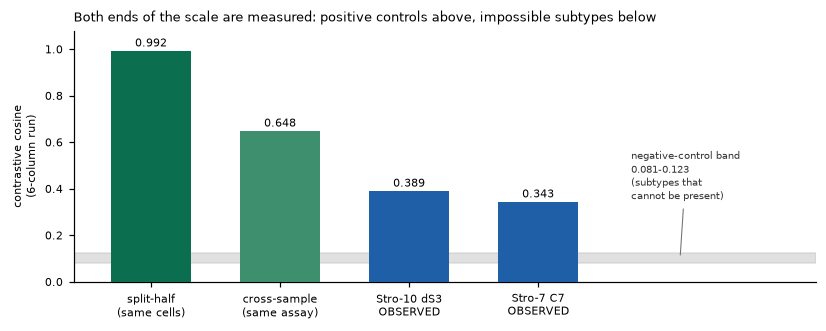

In [9]:
fig, ax = plt.subplots(figsize=(7.6, 3.1))
ax.axhspan(NEG_LO, NEG_HI, color="#c8c8c8", alpha=.55, zorder=0)
# annotate the band in clear space to the right of the last bar, not over the bars
ax.annotate(f"negative-control band\n{NEG_LO:.3f}-{NEG_HI:.3f}\n"
            "(subtypes that\ncannot be present)",
            xy=(4.10, (NEG_LO+NEG_HI)/2), xytext=(3.72, 0.34), fontsize=6.5, color="0.2",
            ha="left", va="bottom", linespacing=1.35,
            arrowprops=dict(arrowstyle="-", lw=.7, color="0.45"))
bars = [("split-half\n(same cells)", CEIL1, "#0b6e4f"),
        ("cross-sample\n(same assay)", CEIL2, "#3d8f6d"),
        ("Stro-10 dS3\nOBSERVED", REAL10, "#1f5fa8"),
        ("Stro-7 C7\nOBSERVED", REAL7, "#1f5fa8")]
for i, (lab, v, col) in enumerate(bars):
    ax.bar(i, v, width=.62, color=col, zorder=3)
    ax.text(i, v + .02, f"{v:.3f}", ha="center", fontsize=7.4, zorder=4)
ax.set_xticks(range(len(bars))); ax.set_xticklabels([b[0] for b in bars], fontsize=7)
ax.set_ylabel("contrastive cosine\n(6-column run)", fontsize=7.5)
ax.set_ylim(0, 1.08); ax.set_xlim(-0.6, 5.15); ax.tick_params(labelsize=7)
ax.set_title("Both ends of the scale are measured: positive controls above, "
             "impossible subtypes below", loc="left", fontsize=8.2)
for s in ("top","right"): ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig("SUM1_calibration_ladder.png", dpi=300, bbox_inches="tight")
print(f"Stro-7 sits {(REAL7-NEG_HI)/(CEIL2-NEG_HI):.0%} of the way from the floor to the "
      f"realistic ceiling; Stro-10 {(REAL10-NEG_HI)/(CEIL2-NEG_HI):.0%}")

**The honest reading, which belongs in the paper.** Stro-7 at 0.343 clears the impossible-subtype
floor by ~2.8× and sits about 42% of the way to the cross-sample ceiling. But note the
`best non-self` column: in rung 2, *known non-matching* clusters of our own data score 0.367 on
average against each other — **higher than the real Stro-7 score**. Sibling fibroblast clusters
along a decidualisation continuum genuinely resemble one another, so a score in this range does not
by itself establish identity.

That is exactly why the pipeline never decides on score alone. Three quantities, three jobs:
**score** (is there a partner), **margin** (is the pick resolved or a coin flip), **control ceiling**
(is it above what impossible subtypes get) — plus reciprocity and per-section replication. §4 shows
all of them.

In [11]:
pc = pd.read_csv(find("positive_control_per_cluster_human.csv"), index_col=0)
display(pc)
worst = pc.rung2_self.idxmin()
verify("the least reproducible cluster across samples is also one with no atlas correspondence",
       str(pc.loc[worst, "atlas_call"]), "-", note=f"cluster {worst}, rung-2 self only "
       f"{pc.loc[worst,'rung2_self']:.3f} and {pc.loc[worst,'rung2_recovers']:.0%} recovery")
verify("but cluster 2 is highly reproducible AND has no atlas correspondence",
       bool(pc.loc[2,"rung2_self"] > 0.75 and pc.loc[2,"atlas_call"] == "-"), True,
       note="a real, stable population the atlas simply lacks — a different situation from cluster 4")

       rung1_self  rung1_recovers  rung2_self  rung2_min  rung2_recovers             atlas_call
query                                                                                          
0          0.9931             1.0      0.7323     0.6094          1.0000         Stro-11 (n.s.)
1          0.9933             1.0      0.6750     0.5321          1.0000  Stro-10 dS3 confident
2          0.9975             1.0      0.8033     0.7210          1.0000                      -
3          0.9949             1.0      0.7921     0.6950          1.0000    Stro-7 C7 confident
4          0.9847             1.0      0.3638     0.0544          0.7333                      -
5          0.9898             1.0      0.5195     0.2078          1.0000    Stro-8 dS1 probable
[PASS ] the least reproducible cluster across samples is also one with no atlas correspondence: recomputed=-  recorded=-   (cluster 4, rung-2 self only 0.364 and 73% recovery)
[PASS ] but cluster 2 is highly reproducible AND has no 

**The positive control does more than calibrate — it separates two kinds of "no match".** Both
cluster 2 and cluster 4 map to no atlas subtype, but for opposite reasons: cluster 2 is one of the
*most* reproducible clusters across samples (self-score 0.803), so it is a real population the
atlas does not contain; cluster 4 is the *least* reproducible (0.364, and it fails to recover
itself in 27% of cross-sample tests, always losing to cluster 5), so it is not a robust population
in the first place. Without the positive control those two look identical in the results table.

---
## §4 The human result, at three levels of independence

The published mapping is centroid-level. Everything in this section is additionally **cluster-free**
— computed per cell, with `cell_subtype` used only for display — and **non-circular**: the cosine's
gene panel has every atlas marker gene removed, so the metric is asked to predict genes it never
saw. Three rungs of independence:

1. **held out** — marker genes removed from the panel. Removes direct circularity; gene
   co-expression remains, so the claim is *"never given C7 and still predicts it"*, not *"knows
   nothing about C7"*.
2. **cross-lab** — Fitzgerald et al.'s independently derived C12 gene list, with *both* marker
   sources excluded from the panel. Different lab, different patients, different pipeline.
3. **cross-species** — §5.

In [14]:
c7h  = pd.read_csv(find("human_C7_vs_all_cosines.csv"), index_col=0)["rho"]
fz   = pd.read_csv(find("human_fitzC12_vs_all_cosines.csv"), index_col=0)["rho"]
mgh  = pd.read_csv(find("human_per_marker_gene_correlations.csv"))
rho  = pd.read_csv(find("clusterfree_cell_level_rho.csv"))
CTRL = ["Stro-1","Stro-2","Stro-3","Stro-4","Stro-6"]
FIB  = ["Stro-5","Stro-7","Stro-8","Stro-9","Stro-10","Stro-11"]

print("C7 expression (held out of the panel) vs the per-cell cosine to each subtype:")
display(c7h.sort_values(ascending=False).round(4).to_frame("rho").T)
verify("C7 correlates most with the Stro-7 cosine of all 11 subtypes", c7h.idxmax(), "Stro-7")
verify("every OTHER fibroblast subtype correlates negatively with C7",
       bool((c7h[[f for f in FIB if f != 'Stro-7']] < 0).all()), True,
       note="Stro-8 %.3f, Stro-10 %.3f, Stro-5 %.3f" % (c7h["Stro-8"], c7h["Stro-10"], c7h["Stro-5"]))
verify("cross-lab: the Fitzgerald C12 module also peaks on Stro-7", fz.idxmax(), "Stro-7",
       note=f"rho {fz.max():.4f}, and the controls go strongly negative "
            f"(Stro-2 {fz['Stro-2']:+.3f}, Stro-1 {fz['Stro-1']:+.3f})")

home = mgh.groupby("subtype").hits_own.agg(["mean","size"])
ceil_home = home.loc[CTRL, "mean"].max()
verify("Stro-7's own markers point back to it more often than any other subtype's do",
       home["mean"].idxmax(), "Stro-7",
       note=f"{home.loc['Stro-7','mean']:.1%} of {int(home.loc['Stro-7','size'])} markers, "
            f"vs a {ceil_home:.1%} control ceiling")
verify("the two subtypes with no counterpart sit at the bottom",
       bool(home.loc["Stro-5","mean"] < 0.05 and home.loc["Stro-9","mean"] < 0.05), True,
       note=f"Stro-5 {home.loc['Stro-5','mean']:.1%}, Stro-9 {home.loc['Stro-9','mean']:.1%}")

rh = rho[rho.species=="human"].set_index("centroid")
ceil_rho = rh.loc[CTRL, "rho_cell"].max()
verify("group-free: the marker climb along the cosine axis clears the control ceiling for Stro-7",
       bool(rh.loc["Stro-7","rho_cell"] > ceil_rho), True,
       note=f"{rh.loc['Stro-7','rho_cell']:.3f} vs {ceil_rho:.3f} = "
            f"{rh.loc['Stro-7','rho_cell']/ceil_rho:.1f}x")
verify("and dS2 sits at or below zero, as §1 predicts for a subtype with no specific markers",
       bool(rh.loc["Stro-9","rho_cell"] <= 0), True, note=f"{rh.loc['Stro-9','rho_cell']:+.4f}")

C7 expression (held out of the panel) vs the per-cell cosine to each subtype:
     Stro-7  Stro-4  Stro-3  Stro-2  Stro-1  Stro-6  Stro-10  Stro-9  Stro-11  Stro-8  Stro-5
rho  0.0961   0.038  0.0275  0.0247  0.0218   0.019  -0.0478 -0.0491  -0.0539 -0.0588 -0.0591
[PASS ] C7 correlates most with the Stro-7 cosine of all 11 subtypes: recomputed=Stro-7  recorded=Stro-7
[PASS ] every OTHER fibroblast subtype correlates negatively with C7: recomputed=True  recorded=True   (Stro-8 -0.059, Stro-10 -0.048, Stro-5 -0.059)
[PASS ] cross-lab: the Fitzgerald C12 module also peaks on Stro-7: recomputed=Stro-7  recorded=Stro-7   (rho 0.1541, and the controls go strongly negative (Stro-2 -0.177, Stro-1 -0.146))
[PASS ] Stro-7's own markers point back to it more often than any other subtype's do: recomputed=Stro-7  recorded=Stro-7   (69.4% of 49 markers, vs a 31.2% control ceiling)
[PASS ] the two subtypes with no counterpart sit at the bottom: recomputed=True  recorded=True   (Stro-5 2.0%, Stro-9 2

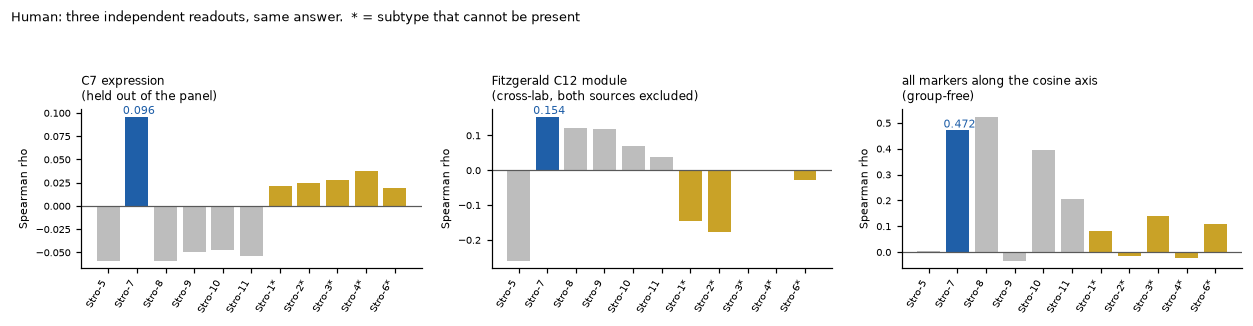

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.0))
panels = [(c7h, "C7 expression\n(held out of the panel)", "Stro-7"),
          (fz,  "Fitzgerald C12 module\n(cross-lab, both sources excluded)", "Stro-7"),
          (rh.rho_cell.reindex(FIB+CTRL), "all markers along the cosine axis\n(group-free)", "Stro-7")]
for ax, (ser, title, hero) in zip(axes, panels):
    s = ser.reindex(FIB + CTRL)
    cols = ["#1f5fa8" if i == hero else ("#c9a227" if i in CTRL else "#bdbdbd") for i in s.index]
    ax.bar(range(len(s)), s.values, color=cols)
    ax.axhline(0, color="0.35", lw=.8)
    ax.set_xticks(range(len(s)))
    ax.set_xticklabels([i + ("*" if i in CTRL else "") for i in s.index], rotation=60,
                       ha="right", fontsize=6.6)
    ax.set_title(title, loc="left", fontsize=7.6)
    ax.set_ylabel("Spearman rho", fontsize=7); ax.tick_params(labelsize=6.6)
    for sp_ in ("top","right"): ax.spines[sp_].set_visible(False)
    ax.text(list(s.index).index(hero), s[hero], f" {s[hero]:.3f}", fontsize=7,
            ha="center", va="bottom", color="#1f5fa8")
fig.suptitle("Human: three independent readouts, same answer.  * = subtype that cannot be present",
             x=.005, ha="left", fontsize=8.6)
fig.tight_layout(rect=(0,0,1,.93))
fig.savefig("SUM2_human_three_levels.png", dpi=300, bbox_inches="tight")

---
## §5 The mouse result, and the three readouts that fail

**The claim.** The C7 fibroblast *programme* is conserved in **eFib1** (outer endometrial
fibroblast) — but the gene *C7* is not the conserved element; **TNXB** and **SCN7A** are.

Ten readouts were run. Seven support the claim, three fail, and all three failures share one
cause: **aggregate 50-gene marker sets do not discriminate across species.** Ortholog-translated
perivascular and mesenchymal sets share ECM genes with everything, so control sets climb along any
fibroblast-like axis. Individual genes and grouped assignment escape that.

In [17]:
led = pd.read_csv(find("mouse_stro7_evidence_ledger.csv"))
display(led[["readout","stro7_mouse_result","verdict"]])
verify("seven of ten mouse readouts support the eFib1 <-> Stro-7 correspondence",
       int((led.verdict=="SUPPORTS").sum()), 7)
verify("all three failures are marker-SET or single-gene, never the assignment itself",
       int((led.verdict=="FAILS").sum()), 3)

q = pd.read_csv(find("TABLE_correspondence_mouse_by_query.csv"), index_col=0)
q["picks_stromal"] = q.best_atlas.str.startswith("Stro-")
display(q)
verify("only 3 of 9 mouse populations pick ANY stromal subtype when all 39 compete",
       int(q.picks_stromal.sum()), 3,
       note="so this is programme-level similarity, not cell-identity assignment")
verify("eFib1 -> Stro-7 is reciprocal", bool(q.loc["eFib1","reciprocal"]), True,
       note=f"score {q.loc['eFib1','score']:.4f}, margin {q.loc['eFib1','margin']:.4f}")

mgm = pd.read_csv(find("mouse_per_marker_gene_correlations.csv"))
hm  = mgm.groupby("subtype").hits_own.mean()
verify("mouse: Stro-7's markers point home at nearly twice the control rate",
       bool(hm["Stro-7"] > hm[CTRL].max()), True,
       note=f"{hm['Stro-7']:.1%} vs {hm[CTRL].max():.1%} ceiling")
c7m = pd.read_csv(find("mouse_C7_vs_all_cosines.csv"), index_col=0)["rho"]
verify("but C7 itself does NOT transfer — its best mouse partner is a negative control",
       str(c7m.idxmax()), "Stro-3", note=f"rho {c7m.max():.4f}; Stro-7 only {c7m['Stro-7']:.4f}")
s7m = mgm[(mgm.subtype=="Stro-7") & (mgm.gene.str.upper().isin(["TNXB","SCN7A","APOD"]))]
display(s7m[["gene","rho_own","best_subtype","hits_own"]].round(4))
verify("the conserved genes are TNXB and SCN7A, both pointing home",
       int(s7m[s7m.gene.str.upper().isin(['TNXB','SCN7A'])].hits_own.sum()), 2)

                                                        readout                                                                              stro7_mouse_result   verdict
0  label-level correspondence (all 39 atlas subtypes competing)                                  eFib1 -> Stro-7, cosine 0.1744, margin 0.0391, reciprocal=True  SUPPORTS
1                                   replication across sections                                Stro-7 -> efib_outer in 9/9 sections; 3/3 within-timepoint pairs  SUPPORTS
2                                               marker ablation                                                survives; no margin crosses zero, smallest 0.025  SUPPORTS
3                                             gene-driver class                                       15/15 top drivers are identity class; panel cosine 0.2429  SUPPORTS
4                          per-cell, grouped on mm_fine_refined                              median cosine 0.0541; 67.8% of eFib1 cells closest to Str

**Do not build a mouse slide on per-cell evidence.** The grouped per-cell readout puts Stro-7 above
its control ceiling and Stro-10 below; the group-free readout inverts that. Two defensible methods
disagree, so the mouse per-cell evidence is method-dependent. The cluster-level result — reciprocal
against all 39 subtypes, replicating in 9/9 sections, 15/15 identity-class drivers — stands on its
own and is what should be shown.

---
## §6 What we do not have evidence for

State these before being asked. Each is a real limit, and §1 explains most of them.

In [20]:
lim = pd.DataFrame([
 ("dS2 (Stro-9) is not resolved", "0 specific markers exist in the atlas; Ulrich separate dS "
  "stages by regulon activity. 'Unresolved' is correct, not a shortfall."),
 ("Stro-5 is not recovered", "Its centroid is NK/T + mast + PTPRC; ~1% of our nuclei are "
  "immune-panel positive. A property of the reference."),
 ("Stro-10 in mouse is diffuse", "Not reciprocal, margin 0.0055, held-out agreement collapses "
  "to 0.254, and per-cell it falls below the control ceiling."),
 ("Stro-8 in mouse is panel-conditional", "Sign flips: -0.087 on the full panel, +0.165/+0.171 "
  "on discriminative panels. Its top label-level hit is the 907-cell ambient sink."),
 ("C7 does not transfer to mouse", "Best mouse partner is a negative control. Use TNXB/SCN7A."),
 ("Mouse mapping is programme-level", "6 of 9 mouse populations map to non-stromal subtypes."),
 ("Scores are not comparable across runs", "Different column sets change both the centring and "
  "the gene panel (trap 1)."),
 ("The C7 module figures are unaudited", "fib_leiden_c7.ipynb has no verify() cells, and its "
  "clusters are leiden 0.8 — different numbering from the leiden 0.5 arm."),
 ("Two donors remains two donors", "Per-section replication (6/6) and cross-sample positive "
  "controls address reproducibility, not population-level generalisation."),
], columns=["we do NOT claim", "why"])
pd.set_option("display.max_colwidth", 120); display(lim)

# DIRECTION MATTERS. rownorm answers "of this 0.8 cluster, what fraction sits in that 0.5
# cluster"; colnorm answers the reverse. Containment of a 0.5 cluster inside a 0.8 cluster is a
# COLUMN-normalised statement, and reading it off the row-normalised table gives 0.744 instead
# of 0.940 — the same pair of clusters, the opposite question.
xw_r = pd.read_csv(find("crosswalk_leiden08_vs_leiden05_rownorm.csv"), index_col=0)
xw_c = pd.read_csv(find("crosswalk_leiden08_vs_leiden05_colnorm.csv"), index_col=0)
for _t in (xw_r, xw_c):
    _t.index = _t.index.astype(str); _t.columns = _t.columns.astype(str)
verify("rownorm rows sum to 1 (so it is the 'of this 0.8 cluster' table)",
       bool((xw_r.sum(axis=1).round(3) == 1).all()), True)
verify("colnorm columns sum to 1 (so it is the 'of this 0.5 cluster' table)",
       bool((xw_c.sum(axis=0).round(3) == 1).all()), True)
verify("the two C7 analyses are on different partitions: 94% of leiden-0.5 c3 sits in leiden-0.8 c5",
       round(float(xw_c.loc["5","3"]), 3), 0.940, tol=0.002,
       note="colnorm; so 'cluster 3' names different cells in each analysis — a numbering "
            "collision, not a contradiction")
verify("and the module's peak 0.8 cluster maps mostly onto the Stro-10 cluster, not the Stro-7 one",
       round(float(xw_r.loc["2","1"]), 3), 0.645, tol=0.002,
       note="rownorm; do not say 'the C7 module is most specific to our C7 cluster'")
verify("the anti-C7 0.8 cluster is inside 0.5 cluster 2, not 0.5 cluster 3",
       round(float(xw_r.loc["3","2"]), 3), 0.859, tol=0.002, note="rownorm")

                         we do NOT claim                                                                                                                                  why
0           dS2 (Stro-9) is not resolved      0 specific markers exist in the atlas; Ulrich separate dS stages by regulon activity. 'Unresolved' is correct, not a shortfall.
1                Stro-5 is not recovered                       Its centroid is NK/T + mast + PTPRC; ~1% of our nuclei are immune-panel positive. A property of the reference.
2            Stro-10 in mouse is diffuse               Not reciprocal, margin 0.0055, held-out agreement collapses to 0.254, and per-cell it falls below the control ceiling.
3   Stro-8 in mouse is panel-conditional  Sign flips: -0.087 on the full panel, +0.165/+0.171 on discriminative panels. Its top label-level hit is the 907-cell ambient sink.
4          C7 does not transfer to mouse                                                                            Best mouse par

In [21]:
checks = check_summary()
checks.to_csv("SUMMARY_notebook_selfcheck.csv", index=False)


33 checks | 0 MISMATCH


---
## Figure sequence for a short talk

1. **§1 specificity table** — which subtypes are findable in principle. *Say aloud:* two of the
   eleven have no specific markers, so we predict our own misses before showing them.
2. **§3 calibration ladder** (`SUM1_calibration_ladder.png`) — both ends measured. *Say aloud:*
   the split-half rung is an upper bound, not a target.
3. **§4 three-panel human figure** (`SUM2_human_three_levels.png`) — held-out, cross-lab,
   group-free. *Say aloud:* the marker genes were removed from the panel before the correlation.
4. **Human sink test** (from the compiled notebook) — five impossible subtypes band at
   0.081–0.124, none reciprocal.
5. **Human per-section replication** — 6/6 for Stro-7 and Stro-10; the 3/6 split for Stro-8/9
   falls exactly on the phase boundary.
6. **§5 mouse ledger** — seven readouts supporting, three failing, one cause. *Say aloud:* TNXB
   and SCN7A carry it, not C7.
7. **§6 limits table** — read it out rather than waiting to be asked.

Hold in reserve: the resolution crosswalk (for "didn't you just say cluster 3?"), the robustness
panel (for gene-resampling questions), and the detectability dotplot (for "why no Stro-5").